In [ ]:
# https://www.tensorflow.org/tutorials/images
# https://www.proxpc.com/blogs/tensorflow-lite-real-time-computer-vision-on-edge-devices-2024
# https://automaticaddison.com/how-to-determine-the-orientation-of-an-object-using-opencv/
# https://www.geeksforgeeks.org/machine-learning/image-enhancement-techniques-using-opencv-python/
# https://www.geeksforgeeks.org/python/python-image-blurring-using-opencv/
# https://medium.com/@chinmayiadsul/the-art-of-blur-in-image-processing-part-1-gaussian-blur-made-easy-630eec3c7962
# https://www.geeksforgeeks.org/python/wand-rotational_blur-function-in-python/
# https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html
# https://en.wikipedia.org/wiki/Canny_edge_detector
# https://numpy.org/devdocs/reference/generated/numpy.savez_compressed.html
#https://stackoverflow.com/questions/47520487/how-to-use-python-opencv-to-find-largest-connected-component-in-a-single-channel

# Imports

In [1]:
!pip install pillow matplotlib numpy tifffile scikit-image opencv-python scikit-learn torch torchvision tensorflow pandas

In [2]:
import os
import PIL
import shutil
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from glob import glob
import tifffile

import numpy as np

from skimage import morphology

import cv2

import csv
import random

import math

from math import tan, radians

import glob

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import torch
from torch import nn

import torchvision
import torchvision.transforms as T

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import tensorflow as tf

import pandas as pd

import random

import satellite_cloud_generator as scg

from datetime import datetime

# PIPELINE V2

Loaded successfully: True, shape: (9472, 5844, 3)


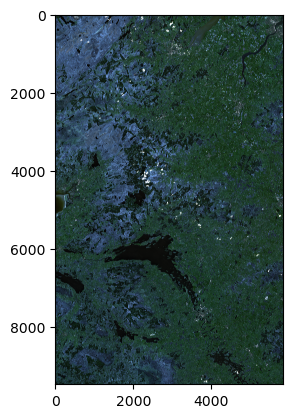

In [6]:
# TBDone
img = Image.open(r"C:\Users\djh20\Downloads\T29UNA_20250402T115421_TCI_10m.png")

# DONE
#img = Image.open(r"C:\Users\djh20\Downloads\T29UNA_20250521T115512_TCI_10m.png") -> LoughErne1ENV
#img = Image.open(r"C:\Users\djh20\Downloads\T29UNA_20250402T115421_TCI_10m.png") -> LoughErne2ENV
#img = Image.open(r"C:\Users\djh20\Downloads\T29UPA_20250521T114401_TCI_10m.png") -> LoughNeagh1
#img = Image.open(r"C:\Users\djh20\Downloads\T29UPA_20250521T114401_TCI_10m.jp2") -> LoughNeagh2
#img = Image.open(r"C:\Users\djh20\Downloads\T29UPA_20250713T114349_TCI_10m.jp2") -> LoughNeagh3ENV

# DUDS (Do not work with data pipeline)
# img = Image.open(r"C:\Users\djh20\Downloads\T29UPA_20260307T114411_TCI_10m.jp2")

img_array = np.array(img)
img_bgr = cv2.cvtColor(img_array, cv2.COLOR_RGB2BGR)

test = img_bgr

plt.imshow(test)

print(f"Loaded successfully: {test is not None}, shape: {test.shape if test is not None else 'N/A'}")

In [7]:
def remover(img):
    # convert to greyscale
    test_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    test_img = np.array(test_img)

    # ensure no pure white images
    white_ratio = np.sum(test_img > 200) / test_img.size
    
    # ensure no pure black image
    black_ratio = np.sum(test_img < 10) / test_img.size
    
    if white_ratio > 0.10:
        return True
    
    if black_ratio > 0.1:
        return True
    
    # there is a lot of white in the image, analyse for clouds
    if white_ratio > 0.01:

        # make mask of clouds
        _, cloud_mask = cv2.threshold(test_img, 140, 255, cv2.THRESH_BINARY)
        #https://stackoverflow.com/questions/47520487/how-to-use-python-opencv-to-find-largest-connected-component-in-a-single-channel
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cloud_mask, connectivity = 8)

        # counters for cloud types
        large = 0
        med = 0
        small = 0

        # find ratio of image uncer cloud cover of various types -  a small amount of cloud is actually good fpr diversity
        for i in range(1, num_labels):
            area_ratio = stats[i, cv2.CC_STAT_AREA] / test_img.size
            area = stats[i, cv2.CC_STAT_AREA]
        
            if area_ratio > 0.02:
                large += 1
                return True
            
            elif area_ratio > 0.08:
                med += 1
                if med > 1:
                    return True
                
            elif 5 < area < 500:
                small += 1
                if small > 5:
                    return True  
    
    # blur the image, find variance
    blur = cv2.GaussianBlur(test_img, (15, 15), 0)
    variance = cv2.absdiff(test_img, blur)

    # if variance is high, means likely large amount of clouds due to pattern 
    if np.mean(variance) > 12:
        return True
        
    return False

In [8]:
def nneighbours(x, y, accepted, min_dist):
    '''
    Checks if a given point is too close to any previously accepted points

    Args:
        x : x coord to check
        y : y coord to check
        accepted : list of (x, y) tuples of accepted points
        min_dist : minimum allowed dist between points

    Returns:
        True if the point is too close to any accepted point, False else
    '''

    # squate the min dist to avoid expensive square rooting 
    # Using square root previously made the pipeline slower
    min_dist_sq = min_dist * min_dist
    
    # check dist with each acceped point
    for xx, yy in accepted:
        # calculate squared distance using Euclidean dist
        dx = x - xx
        dy = y - yy

        # If squared distance is less than min_dist_sq, points are too close
        if dx*dx + dy*dy < min_dist_sq:
            return True
        
    # If no issues, point is far enough
    return False

In [9]:
def monte_carlo_crop(img, num_samples, altitude, num_attempts):
  '''
  Randomly crop high resolution satellite images containing coastline features

  Uses Monte Carlo cropping with multiple filters to find crops that:
    - Contain both land and water (coastline areas)
    - Have sufficient contrast
    - Are spatially separated from each other

  Args:
      img: inpu image in BGR format
      num_samples: number of crops to extract
      altitude: simulated altitude in km
      num_attemps: max attempts per sample before quit

   Returns:
      List of crops that meet criteria
  '''
  res_per_pix = 10 # sentinel resolution for the images im using
  cam_view = 800 * altitude  # cam sees 800m 1km up
  crop_size_pix = int(cam_view/res_per_pix)

  h, w = img.shape[:2]

   # ensure crop doesnt exceed image dims
  if crop_size_pix > min(h, w):
    print('Warning: Crop exceeds image borders. Using maximum possible crop')
    crop_size_pix = min(h, w)

  crops = []

   # extract Hue, Saturation, Value data from image
  hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
  saturation = hsv[:, :, 1]
  value = hsv[:, :, 2]

  grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # THE SAT AND VALUE THRESH NUMBERS HERE ARE WHAT YOU MAY NEED TO CHANGE
  # water: dark (lower value) and low saturation
  water_mask = (
     (value < 80) & (saturation < 60)
  ).astype(np.uint8) * 255
  
  # brighter areas
  land_mask = (value > 100).astype(np.uint8) * 255

  # apply filtering to find regions with both land and water
  kernel_size = min(crop_size_pix // 4, 150)

  water_density = cv2.boxFilter(water_mask, -1, (kernel_size, kernel_size), normalize=True)
  land_density = cv2.boxFilter(land_mask, -1, (kernel_size, kernel_size), normalize=True)

   # calculate a coastal score. Water and land must be present
  mixed = np.minimum(water_density, land_density)

  coast_score = mixed * 0.5

   # get areas og easily discerned coastline
  high_contrast = np.where((coast_score > np.percentile(coast_score, 70))) #| 
  num_huigh_contrast = len(high_contrast[0])

  i = 0 # number of accepted crops

  attempts = 0
  max_attempts = num_samples * num_attempts

  accepted= [] # list of (x, y) tuples for accepted crops

   # minimum distance dependent on the altitude
   # higher alt = more overlap allowed (otherwise get barely any crops)
  if altitude < 10:
     min_dist = crop_size_pix // 8
  elif altitude < 14:
     min_dist = crop_size_pix // 25
  elif altitude < 18:
     min_dist = crop_size_pix // 35
  else:
     min_dist = crop_size_pix // 50

   # track reasons for rejection
  reject_nn = 0
  reject_water = 0
  reject_std = 0
  reject_remove = 0
   
  while i < num_samples and attempts < max_attempts:
        attempts += 1

         # 80% of the time, sample from high quality coast
        if random.random() < 0.8 and num_huigh_contrast > 0:
            idx = random.randint(0, len(high_contrast[0]) - 1)
            y = high_contrast[0][idx]
            x = high_contrast[1][idx]

            # ensure crop stays in bounds
            x = np.clip(x, 0, w - crop_size_pix)
            y = np.clip(y, 0, h - crop_size_pix)
        else:
            # rest of time sample from the rest of the image - ensure diversity for model
            x = random.randint(0, w - crop_size_pix)
            y = random.randint(0, h - crop_size_pix)
      
         # reject if too close to other crop
        if nneighbours(x, y, accepted, min_dist):
           reject_nn += 1
           continue

         # reject if crop is too uniform (farmland, middle of water, yadda yadda)
        crop_gray = grey[y:y+crop_size_pix, x:x+crop_size_pix]
        if np.std(crop_gray) < 15:
            reject_std += 1
            continue

         # check water content in the crop
        crop_val = value[y:y+crop_size_pix, x:x+crop_size_pix]
        crop_sat = saturation[y:y+crop_size_pix, x:x+crop_size_pix]

        water_huepeak = np.sum((crop_val < 80) & (crop_sat < 60))
        tot_pix = crop_val.size

        # find ratio of image that contains image 
        ratio = water_huepeak / tot_pix

         # set minimum allowable water amount
         # as with min dist, higher alt = more lenient
        if altitude < 10:
         min_water_ratio = 0.1
        elif altitude < 14:
         min_water_ratio = 0.03
        elif altitude < 18:
         min_water_ratio = 0.03
        else:
         min_water_ratio = 0.02

         # reject if water coverage insufficnet
        if ratio < min_water_ratio:
         reject_water += 1
         continue
        
        # apply remover for clouds, black border regions 
        crop = img[y:y+crop_size_pix, x:x+crop_size_pix]
        if remover(crop):
          reject_remove +=1
          continue

          # crop makes it
        crops.append(crop)
        accepted.append((x, y))

        i += 1

  print(f"  Got {len(crops)}/{num_samples} crops in {attempts} attempts")
  print(f"  Rejections: neighbor={reject_nn}, std={reject_std}, water={reject_water}, remover={reject_remove}")
  return crops

In [10]:
def crop_rotator(crops, rot_per_crop):
    '''
    Generate multiple rotations per crop

    Each crop rotated bt random angle, then the centre is extracted to remove black borders
    Final crops are resized to 512x512 and greyscaled

    Args:
        crops = List of input crops (BGR)
        rot_per_crop: Number of random rotations to get per crop

    Return:
        tuple: (rotated_crops, angles)
        - rotated_crops: list of 512x512 rotated crops
        - angles: list of rotation angles applied
    '''
    rotated_crops = []
    angles = []

    for crop in crops:
        # resize to max dimension to be more efficient with memory
        h, w = crop.shape[:2]
        if max(h, w) > 512:
            scale = 512 / max(h, w)
            nh, nw = int(h * scale), int(w * scale)
            crop = cv2.resize(crop, (nh, nw))

        # generate multiple rotations per crop
        for _ in range(rot_per_crop):
            # random rotation angle
            angle = random.uniform(0, 360)
            center = (crop.shape[1] // 2, crop.shape[0] // 2)
            rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
            rotated = cv2.warpAffine(crop, rotation_matrix, (crop.shape[1], crop.shape[0]))

            # remove 15% margin from sides to elimante black borders from rotation
            # failure to remove these would mean the model learns the rotation angle from the border, not the feature
            margin = int(crop.shape[0] * 0.15)
            cropped_clean = rotated[margin:-margin, margin:-margin]

            # resize to 512x512
            cropped_clean = cv2.resize(cropped_clean, (512, 512))

            # convert to greyscale for model input
            cropped_clean = cv2.cvtColor(cropped_clean, cv2.COLOR_BGR2GRAY)

            # store
            angles.append(angle)
            rotated_crops.append(cropped_clean)

    return rotated_crops, angles

In [11]:
# homography:
# https://stackoverflow.com/questions/23920729/compute-homography-for-a-virtual-camera-with-opencv/23951677#23951677
# https://opencv.org/blog/image-rotation-and-translation-using-opencv/
# https://medium.com/data-science/image-processing-with-python-applying-homography-for-image-warping-84cd87d2108f

def homography_image(img, dist, ax, maxxyangle, num_tilts):
    '''
    Apply perspective transformation to simulate camera tilt

    Tilt direction is quantised into azimuth angles around a circle to simulate realistic angling

    Args:
        img:  image
        dist: Distance parameter for perspective projection (affects depth) - Not used, stays at 500, must remove
        ax: String specifying rotation axes ('x', 'y', 'xy', 'xz', 'yz')
        maxxyangle: Maximum tilt angle in degrees
        num_tilts: Number of tilt directions
    
    Returns:
        dst: Homographed image
    '''
    h, w = img.shape[:2]

    A1 = np.matrix([[1, 0, -w/2],
                    [0, 1, -h/2],
                    [0, 0, 0],
                    [0, 0, 1]])

    T = np.matrix([[1, 0, 0, 0],
                   [0, 1, 0, 0],
                   [0, 0, 1, dist],
                   [0, 0, 0, 1]])

    A2 = np.matrix([[500, 0, w/2, 0],
                    [0, 500, h/2, 0],
                    [0, 0, 1, 0]])

    # generate random tilt magnitude
    tilt_magnitude = np.random.randint(0, maxxyangle + 1)
    tilt_angle_rad = tilt_magnitude * np.pi/180

    # tilt direction
    tilt_direction_idx = np.random.randint(0, num_tilts)
    tilt_azimuth = (360 / num_tilts) * tilt_direction_idx
    tilt_azimuth_rad = tilt_azimuth * np.pi/180

    # decompose into pitch and yaw components
    pitch_rad = tilt_angle_rad * np.cos(tilt_azimuth_rad) if 'x' in ax else 0
    yaw_rad = tilt_angle_rad * np.sin(tilt_azimuth_rad) if 'y' in ax else 0

    # rotation matrix
    R = np.matrix(np.eye(4))

    # apply pitch
    if 'x' in ax:
            RX = np.matrix([[1, 0, 0, 0],
                    [0, np.cos(pitch_rad), -np.sin(pitch_rad), 0],
                    [0, np.sin(pitch_rad), np.cos(pitch_rad), 0],
                    [0, 0, 0, 1]])
            R = R * RX

    # apply yaw
    if 'y' in ax:
              RY = np.matrix([[np.cos(yaw_rad), 0, np.sin(yaw_rad), 0],
                    [0, 1, 0, 0],
                    [-np.sin(yaw_rad), 0, np.cos(yaw_rad), 0],
                    [0, 0, 0, 1]])
              R = R * RY

    # compute homography
    H = A2 * (T * (R * A1))
    dst = cv2.warpPerspective(img, H, (w, h), flags=cv2.INTER_LINEAR)

    return dst

def env_conds(img):
    '''
    Simulate atmospheric conditions like blurring and haze

    Args:
      img: input image

    Returns:
      image with simulated environemtnal effects
    '''

    # apply random Gaussian blur
    kernel_size = random.choice([3, 5])
    sigma = random.uniform(0.1, 1.5)

    Gaussian = cv2.GaussianBlur(img, (kernel_size, kernel_size), sigma)

    # Apply atmospheric haze
    haze_strength = random.uniform(0, 0.45) # up to 45% haze opacity
    haze_val = random.randint(150, 220) # light grey colour
    haze_lyr = np.full_like(Gaussian, haze_val, dtype = np.float32)
    image = (Gaussian.astype(np.float32) * (1 - haze_strength) + (haze_lyr * haze_strength))

    # random contrast change
    alpha = random.uniform(0.6, 1.4)
    im = 127 + alpha * (image - 127)

    im = np.clip(im, 0, 255).astype(np.uint8)

    return im

def add_gaussian_noise(img, noise_level):
  '''
  Add gaussian noise to simulate sensor noise

  Args:
        img: image
        noise_level: level of nosie applied
    
  Returns:
        im: image with added Gaussian noise
  '''
  # generate random Gaussian nosie
  noise = np.random.normal(0, noise_level*255, img.shape)
  noise_add = np.clip(img + noise, 0, 255).astype(np.uint8)

  return noise_add


def flight_conds(img):
  '''
  Simulate flight conditions TupperSat likely to experience, apply homgraphy, environmental conditions

  Args:
        img: image
  
  Returns:
        img_env:
          img with flight conditions applied 
  '''

  # randomly choose tilt direction and amount of tilt
  dec_tilt = np.random.randint(0, 2)
  tilt_angle = np.random.randint(0, 3)

  if dec_tilt == 0:
    img_homo = homography_image(img, 500, 'xz', tilt_angle, 1)

  elif dec_tilt == 1:
    img_homo = homography_image(img, 500, 'yz', tilt_angle, 1)

  # apply environmental conditions
  img_env = env_conds(img_homo)

  # add sensor noise
  img_env = add_gaussian_noise(img_env, 0.001)

  return img_env

In [12]:
# Put everything together

all_crops = []
all_angles = []
all_alts = []

# For final flight data set, make sure range is granular over ops window - range(7, 23)

# altitudes list 
altitudes = [14, 20]
cons = 0
for alt in altitudes:
    print(f'Alt: {alt}')       
#                           image  num_crops, alt, attempts
    crops = monte_carlo_crop(test, 5, alt, 100)
                                    # crops, number of rotations
    rotated, angles = crop_rotator(crops, 1)

    for crop in rotated:

        dec_crop = np.random.randint(0, 8)
        
        if dec_crop == 0:       
            crop = flight_conds(crop)
        
        all_crops.append(crop)

    all_angles.extend(angles)
    all_alts.extend([alt] * len(rotated))

print(f'Original crops: {len(crops)}')
print(f'After rotation: {len(all_crops)}')

# turn images, angles and alts into arrays
images = np.array(all_crops)
# cos, sin encoding of angles
angles_encoded = np.array([[np.cos(np.radians(a)), np.sin(np.radians(a))] for a in all_angles])
alts_array = np.array(all_alts)

print(f"Images shape: {images.shape}")
print(f"Angles shape: {angles_encoded.shape}")
print(f"Alts shape: {alts_array.shape}")

Alt: 14
  Got 5/5 crops in 27 attempts
  Rejections: neighbor=0, std=0, water=21, remover=1
Alt: 20
  Got 5/5 crops in 20 attempts
  Rejections: neighbor=0, std=0, water=15, remover=0
Original crops: 5
After rotation: 10
Images shape: (10, 512, 512)
Angles shape: (10, 2)
Alts shape: (10,)


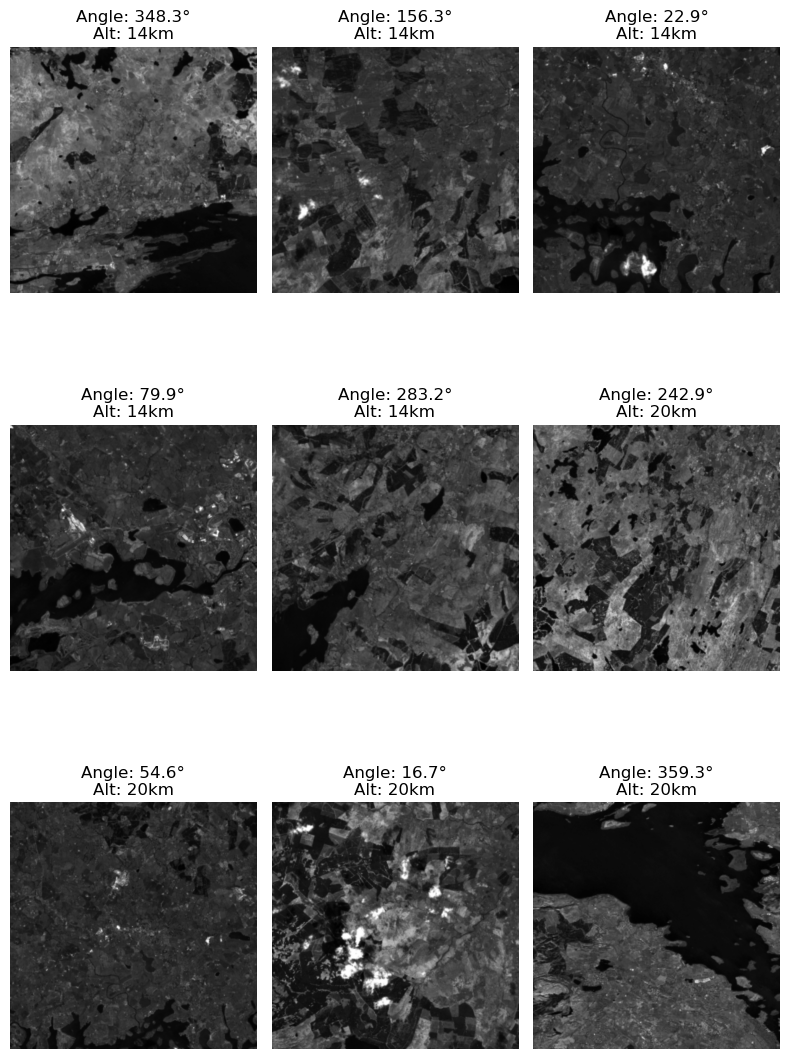

In [15]:
# Rudimentary plotting code
num = 3

fig, axes = plt.subplots(num, num, figsize=(8, 12))
axes = axes.flatten()

for i in range(min((num * num), len(images))):
    axes[i].imshow(images[i], cmap = 'gray')
    
    angle_deg = np.degrees(np.arctan2(angles_encoded[i, 1], angles_encoded[i, 0])) % 360
    
    axes[i].set_title(f'Angle: {angle_deg:.1f}°\nAlt: {alts_array[i]}km')
    axes[i].axis('off')

plt.tight_layout()
plt.show()


In [15]:
# Save the dataset with custom timestamp

timestamp = datetime.now().strftime("%Y%m%d")

# MAKE SURE YOU GIVE DATA FILES EXPRESSIVE NAMES

location = input("Please enter the location this data pertains to:")

# np.savez_compressed - lossles saving similar to how zip files are compressed
np.savez_compressed(
    f'{location}_{timestamp}.npz',
    images = images,
    angles = angles_encoded,
    altitudes = alts_array,
)

print(f"Saved: {location}_{timestamp}.npz")

Saved: LoughNeagh3_20260410.npz
